In [ ]:
# prerequisites
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.autograd import Variable
from torchvision.utils import save_image

from VAE import VAE

from matplotlib import colors
import matplotlib.pyplot as plt

import numpy as np

데이터 셋 로더

In [72]:
import os
import pandas as pd
from torch.utils.data import Dataset, DataLoader

class CSVDataset(Dataset):
    def __init__(self, directory, transform=None):
        self.directory = directory
        self.transform = transform

        numerical = lambda _: int(''.join(filter(str.isdigit, _)))
        self.file_names = []
        for set in os.listdir(directory):
            csv_files = sorted((f for f in os.listdir(os.path.join(directory, set)) if f.endswith('.csv')), key = numerical)
            self.file_names.extend(list(map(lambda _:os.path.join(set, _), csv_files)))
        
        # self.file_names = [os.path.join(set, f)
        #                    for set in os.listdir(directory)
        #                    for f in os.listdir(os.path.join(directory, set)) if f.endswith('.csv')]

    def __len__(self):
        return len(self.file_names)

    def __getitem__(self, idx):
        file_path = os.path.join(self.directory, self.file_names[idx])
        data = pd.read_csv(file_path, header=None, index_col=False).values
        data = data.astype('float32')
        
        if self.transform:
            data = self.transform(data)

        assert data.shape == (64, 32), f"Data shape mismatch: got {data.shape}, expected (64, 32)"

        return torch.tensor(data), 0

(학습용) 데이터 셋 로더 인스턴스 만들기

In [73]:
# Define transformations if any
transform = None

# Dataset directories
input_dir = './vae_input_simple'
train_directory = input_dir
test_directory = input_dir

# Create datasets
train_dataset = CSVDataset(directory=train_directory, transform=transform)
test_dataset = CSVDataset(directory=test_directory, transform=transform)

# Data Loader (Input Pipeline)
bs = 32
train_loader = DataLoader(dataset=train_dataset, batch_size=bs, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=bs, shuffle=False)

학습할 토폴로지 디렉토리

In [74]:
reconstructed_dir = './vae_output_simple/'
os.makedirs(reconstructed_dir, exist_ok=True)

모델 인스턴스

In [1]:
# build model
z_dim = 10

vae = VAE(x_dim=64*32, h_dim1= 512, h_dim2=256, z_dim=z_dim)
if torch.cuda.is_available():
    vae.cuda()

vae

NameError: name 'VAE' is not defined

Loss 및 최적화 알고리즘

In [76]:
optimizer = optim.Adam(vae.parameters())
# return reconstruction error + KL divergence losses
def loss_function(recon_x, x, mu, log_var):
    BCE = F.binary_cross_entropy(recon_x, x.view(-1, 64*32), reduction='sum')
    KLD = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())
    return BCE + KLD

vae

In [77]:
def train(epoch):
    vae.train()
    train_loss = 0
    for batch_idx, (data, _) in enumerate(train_loader):
        data = data.cuda()
        optimizer.zero_grad()
        
        recon_batch, mu, log_var = vae(data)
        loss = loss_function(recon_batch, data, mu, log_var)
        
        loss.backward()
        train_loss += loss.item()
        optimizer.step()
        
        if batch_idx % 100 == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss.item() / len(data)))
    print('====> Epoch: {} Average loss: {:.4f}'.format(epoch, train_loss / len(train_loader.dataset)))

In [78]:
def test():
    vae.eval()
    test_loss= 0
    with torch.no_grad():
        for data, _ in test_loader:
            data = data.cuda()
            recon, mu, log_var = vae(data)
            
            # sum up batch loss
            test_loss += loss_function(recon, data, mu, log_var).item()
        
    test_loss /= len(test_loader.dataset)
    print('====> Test set loss: {:.4f}'.format(test_loss))

In [79]:
for epoch in range(1, 1001):
    train(epoch)
    test()

Train Epoch: 1 [0/15 (0%)]	Loss: 1421.674219
====> Epoch: 1 Average loss: 1421.6742
====> Test set loss: 1398.8342
Train Epoch: 2 [0/15 (0%)]	Loss: 1396.567057
====> Epoch: 2 Average loss: 1396.5671
====> Test set loss: 1357.6003
Train Epoch: 3 [0/15 (0%)]	Loss: 1365.600260
====> Epoch: 3 Average loss: 1365.6003
====> Test set loss: 1307.7259
Train Epoch: 4 [0/15 (0%)]	Loss: 1312.946354
====> Epoch: 4 Average loss: 1312.9464
====> Test set loss: 1218.1699
Train Epoch: 5 [0/15 (0%)]	Loss: 1233.602604
====> Epoch: 5 Average loss: 1233.6026
====> Test set loss: 1165.5687
Train Epoch: 6 [0/15 (0%)]	Loss: 1150.767839
====> Epoch: 6 Average loss: 1150.7678
====> Test set loss: 1171.2605
Train Epoch: 7 [0/15 (0%)]	Loss: 1154.104427
====> Epoch: 7 Average loss: 1154.1044
====> Test set loss: 1144.5215
Train Epoch: 8 [0/15 (0%)]	Loss: 1134.620052
====> Epoch: 8 Average loss: 1134.6201
====> Test set loss: 1091.4902
Train Epoch: 9 [0/15 (0%)]	Loss: 1082.563216
====> Epoch: 9 Average loss: 1082.5

In [80]:
input_loader = DataLoader(dataset=train_dataset, batch_size=1, shuffle=False)

30


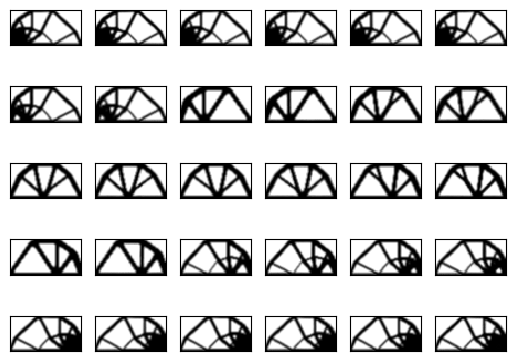

In [81]:
with torch.no_grad():
    latents = []
    for batch_idx, (data, _) in enumerate(input_loader):
        # Move data to GPU if available
        data = data.cuda()
        restored, latent, _ = vae.forward(data)
        latents.append(latent)

        pd.DataFrame(data.cpu().view(64, 32)).to_csv(f'{reconstructed_dir}/{batch_idx}_data.csv', index=False, header=False)
        pd.DataFrame(restored.cpu().view(64, 32)).to_csv(f'{reconstructed_dir}/{batch_idx}_rest.csv', index=False, header=False)


        # save_image(data.view(1, 1, 64, 32), f'./vae_output/{batch_idx}_data' + '.png')
        # save_image(restored.view(1, 1, 64, 32), f'./vae_output/{batch_idx}_restored' + '.png')

from csv2fig import csv2fig
csv2fig(reconstructed_dir, reconstructed_dir, False)

latent space 맵핑

In [82]:
# Extract x and y coordinates from the tensors

coords = np.array([[np.array(tensor[0][i].item()) for tensor in latents] for i in range(z_dim)]).T

# x_coords = [tensor[0][0].item() for tensor in latents]
# y_coords = [tensor[0][1].item() for tensor in latents]

# # Scatter plot with index as color
# plt.scatter(x_coords, y_coords, c=range(len(latents)), cmap='viridis')
# plt.colorbar(label='Index')
# plt.xlabel('X coordinate')
# plt.ylabel('Y coordinate')
# plt.title('Scatter Plot of Tensors with Index as Color')
# plt.show()

In [83]:
from scipy.interpolate import BSpline, make_interp_spline

c_index = np.array([0]+list(range(5,57,4))+[62])
print(c_index)

# b = make_interp_spline(c_index, np.c_[np.array(x_coords), np.array(y_coords), np.array(z_coords)])

b = make_interp_spline(c_index, coords)

# phi_new = np.linspace(0, 62, 100)
# x_new, y_new = b(phi_new).T

# plt.plot(x_coords, y_coords, 'o')
# plt.plot(x_new, y_new, '-')
# plt.show()

[ 0  5  9 13 17 21 25 29 33 37 41 45 49 53 62]


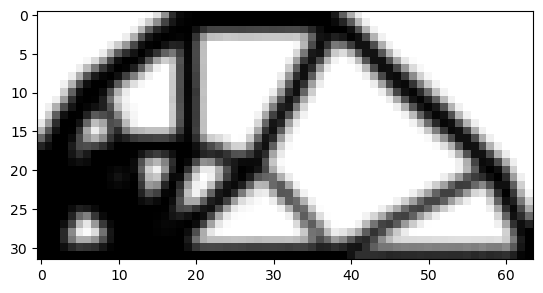

In [84]:
with torch.no_grad():
    sample = vae.decoder(torch.tensor(b(13), dtype=torch.float).cuda())


n1 = pd.DataFrame(sample.cpu().view(64, 32)).to_numpy()

_,ax = plt.subplots()
ax.imshow(-n1.reshape((64,32)).T, cmap='gray', interpolation='none', norm=colors.Normalize(vmin=-1,vmax=0))
plt.show()

63


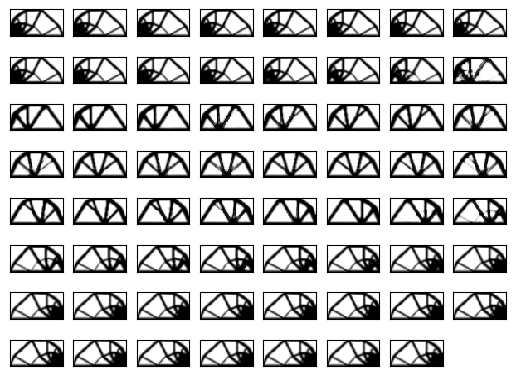

In [85]:
interpolated_dir = reconstructed_dir+'interpolated/'

from FEA_Comp import fea_c
from bc_options import *

c_list = []

for i in range(0, 63):
    with torch.no_grad():
        sample = vae.decoder(torch.tensor(b(i), dtype=torch.float).cuda())
    
    sampledf = pd.DataFrame(sample.cpu().view(64, 32))
    sampledf.to_csv(f'{interpolated_dir}/{i}_interpolated.csv', index=False, header=False)
    c_list.append(fea_c(64, 32, Simple, 3, 65+i*33, sampledf.to_numpy()))

from csv2fig import csv2fig
csv2fig(interpolated_dir, interpolated_dir, False)

#c_list

1. 두 결과의 유사도를 따진다.
2. 컴플라이언스 계산. 일단 이건 바로 할 수 있지 않나:

아무튼: simp로 얻은 것들에 대한 컴플라이언스를 다시 계산하라고 시켜야 한다.

"C:\Users\User\OneDrive\Desktop\topogen\64x32\Simple_64x32_3" 안의 CSV 파일을 순서대로 열어서, 넘파이로 고치고 하면 된다.

In [86]:
import os
import pandas as pd

# very ugly encapsulation
def csv2numpy(directory_path):
    numerical = lambda _: int(''.join(filter(str.isdigit, _)))
    csv_files = sorted((f for f in os.listdir(directory_path) if f.endswith('.csv')), key = numerical)
    num_files = len(csv_files)
    print(num_files)

    c_list = []

    for i, csv_file in enumerate(csv_files):
        file_path = os.path.join(directory_path, csv_file)
        xPhys = pd.read_csv(file_path, header=None, index_col=False).values
        c_list.append(fea_c(64, 32, Simple, 3, 65+i*33, xPhys))
    
    return c_list

c_list_original = csv2numpy("./64x32/Simple_64x32_3")
c_list_original

63


[4.930775206262813,
 6.450401009863818,
 7.520485475587862,
 8.274923204067331,
 8.91375985265332,
 9.498284024173646,
 10.068355529553177,
 10.643544063835629,
 11.239714559374304,
 11.8627044736099,
 12.501642911008672,
 13.169998381435189,
 13.84476987015952,
 14.522851457602247,
 15.18031128994364,
 15.811573103119754,
 16.323744634835133,
 16.912276674694056,
 17.443711547756358,
 17.58034464160116,
 17.571802934545623,
 17.934671571089602,
 18.253552305425657,
 18.6720460078428,
 18.946475258601026,
 19.21156573216159,
 19.45585323063403,
 19.653401919968235,
 19.788043539741693,
 19.974269601913136,
 19.997384103412276,
 20.009630031123002,
 19.997384103408212,
 19.97426960190674,
 19.788043539741114,
 19.653401920017494,
 19.455853230641324,
 19.211565732170932,
 18.946475258558188,
 18.672046007832886,
 18.253552305424513,
 17.93467157108629,
 17.571802934622767,
 17.58034464159507,
 17.443711547758078,
 16.91227667469778,
 16.32374463484316,
 15.811573103121901,
 15.180311289

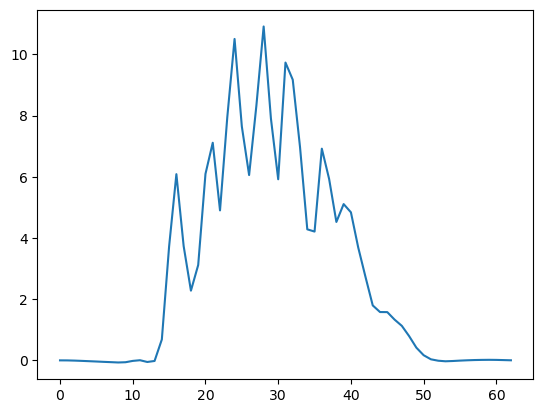

In [87]:
difference = [c_list[i]-c_list_original[i] for i in range(0, 63)]
xaxis = list(range(0, 63))

plt.plot(xaxis, difference)